In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/data_classification1.zip"
extract_path = "/content/dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset extracted successfully!")
print("Top-level folders/files:")

for item in os.listdir(extract_path):
    print(item)

Dataset extracted successfully!
Top-level folders/files:
data_classification1


In [ ]:
for root, dirs, files in os.walk(extract_path):
    level = root.replace(extract_path, '').count(os.sep)
    indent = '  ' * level
    print(f"{indent}{os.path.basename(root)}/")

    if level >= 2:
        dirs[:] = []

    for file in files[:5]:
        print(f"{indent}  {file}")

dataset/
  data_classification1/
    test/
    train/
    valid/


In [ ]:
import os

base_path = "/content/dataset/data_classification1"

for split in ["train", "valid", "test"]:
    split_path = os.path.join(base_path, split)

    print(f"\n========== {split.upper()} ==========")

    classes = sorted([
        d for d in os.listdir(split_path)
        if os.path.isdir(os.path.join(split_path, d))
    ])

    print("Number of classes:", len(classes))
    print("Classes:")
    for c in classes:
        print(" ", c)

    print("Total images:")

    total = 0
    for c in classes:
        class_path = os.path.join(split_path, c)
        count = len([
            f for f in os.listdir(class_path)
            if os.path.isfile(os.path.join(class_path, f))
        ])
        print(f"  {c}: {count}")
        total += count

    print("Total:", total)


========== TRAIN ==========
Number of classes: 28
Classes:
  0
  1
  10
  11
  12
  13
  14
  15
  16
  17
  18
  19
  2
  20
  21
  22
  23
  24
  25
  26
  27
  3
  4
  5
  6
  7
  8
  9
Total images:
  0: 76
  1: 15
  10: 54
  11: 54
  12: 16
  13: 17
  14: 23
  15: 130
  16: 17
  17: 194
  18: 53
  19: 120
  2: 89
  20: 111
  21: 91
  22: 19
  23: 243
  24: 125
  25: 22
  26: 17
  27: 152
  3: 15
  4: 50
  5: 25
  6: 43
  7: 14
  8: 119
  9: 23
Total: 1927

========== VALID ==========
Number of classes: 28
Classes:
  0
  1
  10
  11
  12
  13
  14
  15
  16
  17
  18
  19
  2
  20
  21
  22
  23
  24
  25
  26
  27
  3
  4
  5
  6
  7
  8
  9
Total images:
  0: 25
  1: 1
  10: 11
  11: 8
  12: 3
  13: 3
  14: 6
  15: 21
  16: 3
  17: 43
  18: 9
  19: 37
  2: 21
  20: 27
  21: 15
  22: 3
  23: 53
  24: 33
  25: 4
  26: 3
  27: 25
  3: 6
  4: 9
  5: 7
  6: 5
  7: 1
  8: 20
  9: 5
Total: 407

========== TEST ==========
Number of classes: 28
Classes:
  0
  1
  10
  11
  12
  13
  14
 

In [ ]:
import tensorflow as tf
import numpy as np
import os
import random

from tensorflow.keras import layers, models
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.optimizers import Adam


SEED = 42

np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)


print("TensorFlow version:", tf.__version__)


gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU available:", gpus)
    print("Using GPU")
else:
    print("WARNING: GPU not found. Training will be much slower.")

TensorFlow version: 2.20.0


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)

gpus = tf.config.list_physical_devices('GPU')

if gpus:
    print("GPU available:", gpus)
    print("Using GPU")
else:
    print("WARNING: GPU not found.")

TensorFlow version: 2.20.0
GPU available: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Using GPU


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
import zipfile

zip_path = "/content/drive/MyDrive/data_classification1.zip"
extract_root = "/content/dataset"

os.makedirs(extract_root, exist_ok=True)

with zipfile.ZipFile(zip_path, "r") as zip_ref:
    zip_ref.extractall(extract_root)

print("Extraction completed!")


for root, dirs, files in os.walk(extract_root):
    level = root.replace(extract_root, "").count(os.sep)
    indent = "  " * level
    print(indent + os.path.basename(root) + "/")
    if level >= 2:
        continue

Extraction completed!
dataset/
  data_classification1/
    valid/
      19/
      6/
      4/
      7/
      10/
      14/
      16/
      13/
      17/
      20/
      21/
      3/
      23/
      0/
      12/
      2/
      27/
      5/
      9/
      24/
      1/
      15/
      11/
      25/
      22/
      26/
      18/
      8/
    test/
      19/
      6/
      4/
      7/
      10/
      14/
      16/
      13/
      17/
      20/
      21/
      3/
      23/
      0/
      12/
      2/
      27/
      5/
      9/
      24/
      1/
      15/
      11/
      25/
      22/
      26/
      18/
      8/
    train/
      19/
      6/
      4/
      7/
      10/
      14/
      16/
      13/
      17/
      20/
      21/
      3/
      23/
      0/
      12/
      2/
      27/
      5/
      9/
      24/
      1/
      15/
      11/
      25/
      22/
      26/
      18/
      8/


In [ ]:
import os
import tensorflow as tf

DATASET_ROOT = "/content/dataset/data_classification1"

TRAIN_DIR = os.path.join(DATASET_ROOT, "train")
VALID_DIR = os.path.join(DATASET_ROOT, "valid")
TEST_DIR  = os.path.join(DATASET_ROOT, "test")

IMG_SIZE = (224, 224)


BATCH_SIZE = 32

SEED = 42


class_names = sorted(
    [d for d in os.listdir(TRAIN_DIR)
     if os.path.isdir(os.path.join(TRAIN_DIR, d))],
    key=lambda x: int(x)
)

print("Classes:", class_names)
print("Number of classes:", len(class_names))

train_ds = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True,
    seed=SEED
)

valid_ds = tf.keras.utils.image_dataset_from_directory(
    VALID_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_ds = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    labels="inferred",
    label_mode="categorical",
    class_names=class_names,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("\nDataset loading completed successfully.")

Classes: ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', '21', '22', '23', '24', '25', '26', '27']
Number of classes: 28
Found 1927 files belonging to 28 classes.
Found 407 files belonging to 28 classes.
Found 409 files belonging to 28 classes.

Dataset loading completed successfully.


In [ ]:
from tensorflow.keras import layers, Model
from tensorflow.keras.applications import EfficientNetV2S
from tensorflow.keras.optimizers import Adam

NUM_CLASSES = 28

INPUT_SHAPE = (224, 224, 3)

WEIGHTS = None

base_model = EfficientNetV2S(
    include_top=False,
    weights=WEIGHTS,
    input_shape=INPUT_SHAPE,
    include_preprocessing=False
)

base_model.trainable = True

inputs = layers.Input(shape=INPUT_SHAPE)

x = layers.Rescaling(1.0 / 255.0)(inputs)

x = base_model(x)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)


model = Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetV2S_TSR"
)

model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

Model: "EfficientNetV2S_TSR"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetv2-s (Functional)   │ (None, 7, 7, 1280)     │    20,331,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 28)             │        35,868 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 20,367,228 (77.69 MB)

 Trainable params: 20,213,356 (77.11 MB)

 Non-trainable params: 153,872 (601.06 KB)

In [ ]:
data_augmentation = tf.keras.Sequential([

    # Rotation
    layers.RandomRotation(
        factor=0.08,
        fill_mode="reflect"
    ),


    layers.RandomFlip(
        mode="horizontal_and_vertical"
    ),


    layers.RandomZoom(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),


    layers.RandomTranslation(
        height_factor=0.10,
        width_factor=0.10,
        fill_mode="reflect"
    ),


    layers.RandomContrast(
        factor=0.10
    ),

   
    layers.RandomBrightness(
        factor=0.10
    )

], name="data_augmentation")

print("Data augmentation created successfully.")

Data augmentation created successfully.


In [ ]:
inputs = layers.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = layers.Rescaling(1.0 / 255.0)(x)

x = base_model(x)

x = layers.GlobalAveragePooling2D()(x)

outputs = layers.Dense(
    NUM_CLASSES,
    activation="softmax"
)(x)

model = Model(
    inputs=inputs,
    outputs=outputs,
    name="EfficientNetV2S_TSR"
)


model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

print("Training-ready model created successfully.")
print("Input size:", INPUT_SHAPE)
print("Number of classes:", NUM_CLASSES)
print("Batch size:", BATCH_SIZE)
print("Learning rate:", 0.001)


Training-ready model created successfully.
Input size: (224, 224, 3)
Number of classes: 28
Batch size: 32
Learning rate: 0.001


In [ ]:
EPOCHS = 15

history = model.fit(
    train_ds,
    validation_data=valid_ds,
    epochs=EPOCHS,
    verbose=1
)

print("\nTraining completed!")

Epoch 1/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 137s 812ms/step - accuracy: 0.1199 - loss: 3.1091 - val_accuracy: 0.1720 - val_loss: 3.7631
Epoch 2/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 730ms/step - accuracy: 0.1842 - loss: 2.6830 - val_accuracy: 0.2113 - val_loss: 2.9492
Epoch 3/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 738ms/step - accuracy: 0.2750 - loss: 2.3696 - val_accuracy: 0.3636 - val_loss: 2.0010
Epoch 4/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 731ms/step - accuracy: 0.3446 - loss: 1.9962 - val_accuracy: 0.3833 - val_loss: 1.7928
Epoch 5/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 731ms/step - accuracy: 0.3799 - loss: 1.7971 - val_accuracy: 0.4570 - val_loss: 1.6020
Epoch 6/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 732ms/step - accuracy: 0.4369 - loss: 1.6337 - val_accuracy: 0.4963 - val_loss: 1.4006
Epoch 7/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 743ms/step - accuracy: 0.4587 - loss: 1.5821 - val_accuracy: 0.4496 - val_loss: 1.8584
Epoch 8/15
61/61 ━━━━━━━━━━━━━━━━━━━━ 45s 737ms/step - accuracy: 0.4624 - loss: 1.4960 - val_acc

In [ ]:
test_loss, test_accuracy = model.evaluate(
    test_ds,
    verbose=1
)

print("\n==============================")
print("TEST RESULTS")
print("==============================")
print(f"Test Loss     : {test_loss:.4f}")
print(f"Test Accuracy : {test_accuracy * 100:.2f}%")

print("\n==============================")
print("THESIS REPORTED RESULT")
print("==============================")
print("Accuracy      : 70.34%")
print("Weighted F1   : 0.702")
print("Inference     : 373.98 ms/image")

13/13 ━━━━━━━━━━━━━━━━━━━━ 3s 207ms/step - accuracy: 0.8582 - loss: 0.4354

TEST RESULTS
Test Loss     : 0.4354
Test Accuracy : 85.82%

THESIS REPORTED RESULT
Accuracy      : 70.34%
Weighted F1   : 0.702
Inference     : 373.98 ms/image


In [ ]:
import numpy as np
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

y_true = []
y_pred = []

for images, labels in test_ds:
    predictions = model.predict(images, verbose=0)

    true_labels = np.argmax(labels.numpy(), axis=1)
    predicted_labels = np.argmax(predictions, axis=1)

    y_true.extend(true_labels)
    y_pred.extend(predicted_labels)

y_true = np.array(y_true)
y_pred = np.array(y_pred)

accuracy = accuracy_score(y_true, y_pred)
weighted_precision = precision_score(
    y_true, y_pred, average="weighted", zero_division=0
)
weighted_recall = recall_score(
    y_true, y_pred, average="weighted", zero_division=0
)
weighted_f1 = f1_score(
    y_true, y_pred, average="weighted", zero_division=0
)

print("==============================")
print("EFFICIENTNETV2-S TEST METRICS")
print("==============================")

print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Weighted Precision : {weighted_precision:.4f}")
print(f"Weighted Recall    : {weighted_recall:.4f}")
print(f"Weighted F1        : {weighted_f1:.4f}")

print("\n==============================")
print("THESIS")
print("==============================")
print("Accuracy           : 70.34%")
print("Weighted F1        : 0.702")

EFFICIENTNETV2-S TEST METRICS
Accuracy           : 85.82%
Weighted Precision : 0.8772
Weighted Recall    : 0.8582
Weighted F1        : 0.8499

THESIS
Accuracy           : 70.34%
Weighted F1        : 0.702


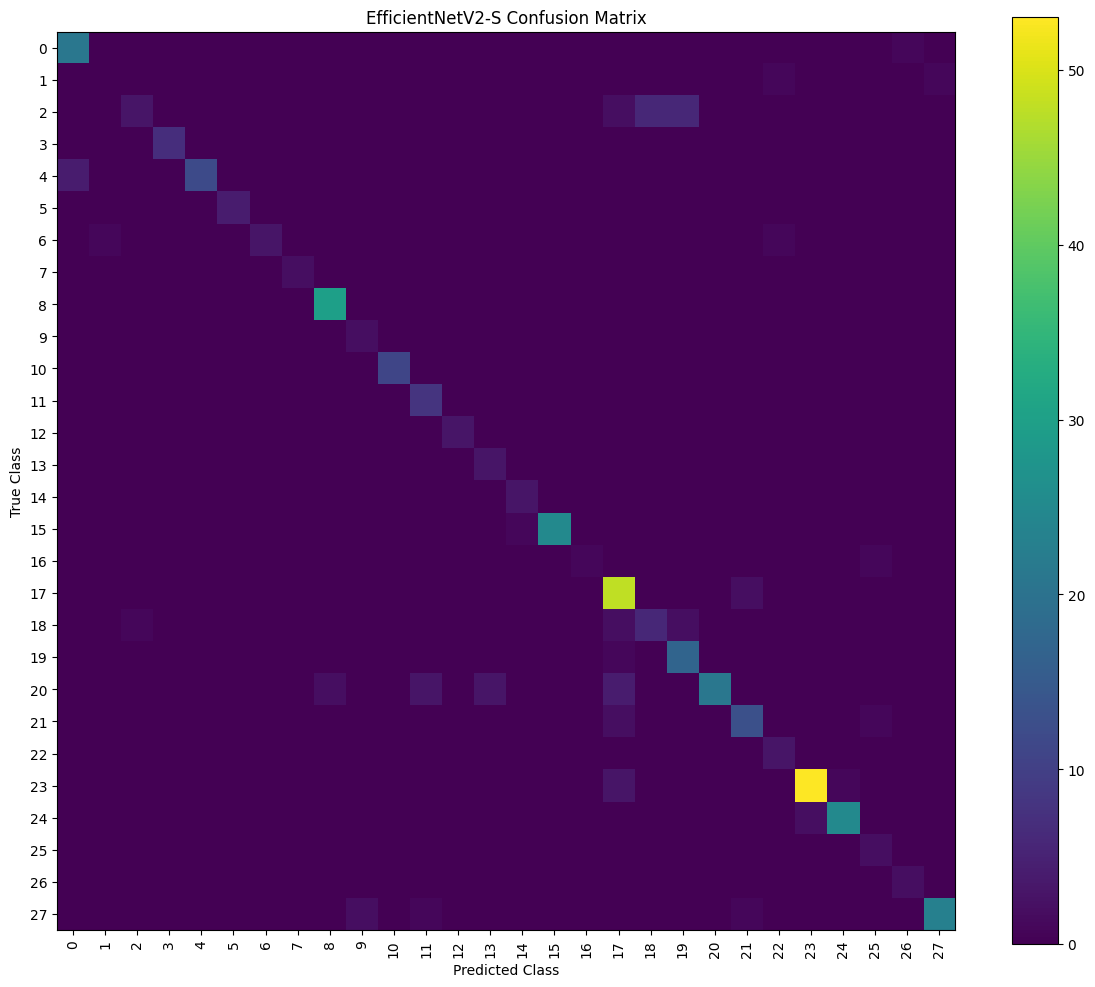

In [ ]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(12, 10))

plt.imshow(cm, interpolation="nearest")
plt.title("EfficientNetV2-S Confusion Matrix")
plt.colorbar()

plt.xticks(
    range(NUM_CLASSES),
    class_names,
    rotation=90
)

plt.yticks(
    range(NUM_CLASSES),
    class_names
)

plt.xlabel("Predicted Class")
plt.ylabel("True Class")

plt.tight_layout()
plt.show()

In [ ]:
import time
import numpy as np

images, labels = next(iter(test_ds))

for _ in range(5):
    _ = model(images, training=False).numpy()

times = []

for _ in range(20):
    start = time.perf_counter()
    predictions = model(images, training=False).numpy()
    end = time.perf_counter()
    times.append(end - start)

avg_batch_time = np.mean(times)
num_images = images.shape[0]
avg_time_per_image_ms = (avg_batch_time / num_images) * 1000

print(f"Average batch inference time: {avg_batch_time:.4f} seconds")
print(f"Batch size: {num_images}")
print(f"Average inference time per image: {avg_time_per_image_ms:.2f} ms")

Average batch inference time: 0.6688 seconds
Batch size: 32
Average inference time per image: 20.90 ms


In [ ]:
for layer in reversed(base_model.layers):
    try:
        output_shape = layer.output.shape
        if len(output_shape) == 4:
            print("Last 4D layer:")
            print("Name:", layer.name)
            print("Type:", layer.__class__.__name__)
            print("Output shape:", output_shape)
            break
    except:
        pass

Last 4D layer:
Name: top_activation
Type: Activation
Output shape: (None, 7, 7, 1280)


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

print("TensorFlow:", tf.__version__)

last_conv_layer_name = "top_activation"

last_conv_layer = base_model.get_layer(last_conv_layer_name)

print("Grad-CAM layer:", last_conv_layer.name)
print("Output shape:", last_conv_layer.output.shape)

TensorFlow: 2.20.0
Grad-CAM layer: top_activation
Output shape: (None, 7, 7, 1280)


In [ ]:
def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name):
    """
    Generate Grad-CAM heatmap for one image.
    """

   
    last_conv_layer = base_model.get_layer(last_conv_layer_name)

    grad_model = tf.keras.models.Model(
        inputs=model.inputs,
        outputs=[
            last_conv_layer.output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:


        conv_outputs, predictions = grad_model(img_array)

        pred_index = tf.argmax(predictions[0])

        class_score = predictions[:, pred_index]

    grads = tape.gradient(class_score, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(1, 2))

    conv_outputs = conv_outputs[0]
    pooled_grads = pooled_grads[0]

    heatmap = tf.reduce_sum(
        conv_outputs * pooled_grads,
        axis=-1
    )

    heatmap = tf.maximum(heatmap, 0)

    max_value = tf.reduce_max(heatmap)

    heatmap = heatmap / (max_value + tf.keras.backend.epsilon())

    return heatmap.numpy(), int(pred_index.numpy())

In [ ]:
images, labels = next(iter(test_ds))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32, 28)


In [ ]:
import tensorflow as tf
import numpy as np

def make_gradcam_heatmap_fixed(
    img_array,
    model,
    base_model,
    last_conv_layer_name
):

   last_conv_layer = base_model.get_layer(
        last_conv_layer_name
    )

    grad_model = tf.keras.models.Model(
        inputs=base_model.input,
        outputs=[
            last_conv_layer.output,
            base_model.output
        ]
    )

   rescaling_layer = model.get_layer("rescaling_1")

    x = rescaling_layer(img_array)

     with tf.GradientTape() as tape:

        conv_outputs, base_output = grad_model(
            x,
            training=False
        )

        pooled_output = model.get_layer(
            "global_average_pooling2d_1"
        )(base_output)

        predictions = model.get_layer(
            "dense_1"
        )(pooled_output)

        predicted_class = tf.argmax(
            predictions[0]
        )

        class_channel = predictions[:, predicted_class]

    grads = tape.gradient(
        class_channel,
        conv_outputs
    )

     pooled_grads = tf.reduce_mean(
        grads,
        axis=(0, 1, 2)
    )

    conv_outputs = conv_outputs[0]

    heatmap = conv_outputs @ pooled_grads[..., tf.newaxis]

    heatmap = tf.squeeze(heatmap)

    heatmap = tf.maximum(
        heatmap,
        0
    )

    max_value = tf.reduce_max(heatmap)

    heatmap = tf.where(
        max_value > 0,
        heatmap / max_value,
        heatmap
    )

    return heatmap.numpy(), int(predicted_class.numpy())

img = images[0]

img_array = tf.expand_dims(
    img,
    axis=0
)

heatmap, predicted_class = make_gradcam_heatmap_fixed(
    img_array,
    model,
    base_model,
    last_conv_layer_name
)

true_class = int(tf.argmax(labels[0]).numpy())

print("True class     :", true_class)
print("Predicted class:", predicted_class)
print("Heatmap shape  :", heatmap.shape)

True class     : 0
Predicted class: 0
Heatmap shape  : (7, 7)


In [ ]:
img = images[0]

img_array = tf.expand_dims(img, axis=0)

heatmap, predicted_class = make_gradcam_heatmap_fixed(
    img_array,
    model,
    base_model,
    last_conv_layer_name
)

true_class = int(tf.argmax(labels[0]).numpy())

print("True class     :", true_class)
print("Predicted class:", predicted_class)
print("Heatmap shape  :", heatmap.shape)

True class     : 0
Predicted class: 0
Heatmap shape  : (7, 7)


In [ ]:
img = images[0]

img_array = tf.expand_dims(img, axis=0)

heatmap, predicted_class = make_gradcam_heatmap_fixed(
    img_array,
    model,
    base_model,
    last_conv_layer_name
)

true_class = int(tf.argmax(labels[0]).numpy())

print("True class     :", true_class)
print("Predicted class:", predicted_class)
print("Heatmap shape  :", heatmap.shape)

True class     : 0
Predicted class: 0
Heatmap shape  : (7, 7)


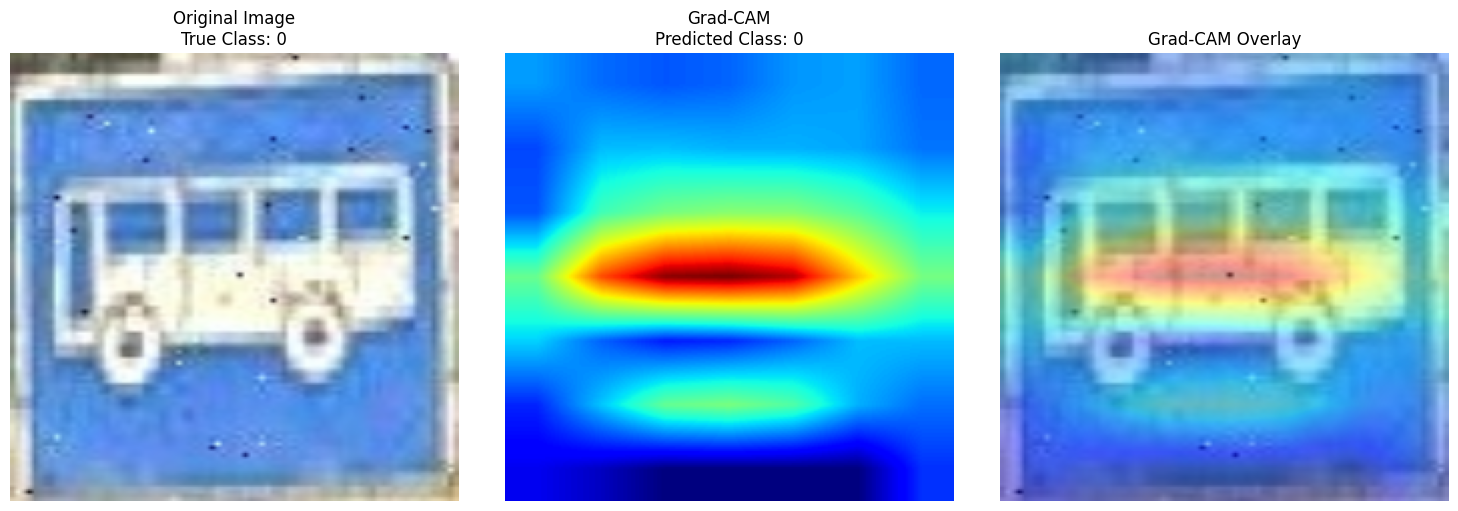

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

original = img.numpy() if tf.is_tensor(img) else img
original = np.array(original)

if original.max() <= 1.5:
    original_display = np.clip(original, 0, 1)
else:
    original_display = np.clip(original / 255.0, 0, 1)


heatmap_resized = tf.image.resize(
    heatmap[..., tf.newaxis],
    (original_display.shape[0], original_display.shape[1])
).numpy().squeeze()

heatmap_uint8 = np.uint8(255 * heatmap_resized)

jet = plt.get_cmap("jet")
jet_colors = jet(np.arange(256))[:, :3]

colored_heatmap = jet_colors[heatmap_uint8]

alpha = 0.4
overlay = colored_heatmap * alpha + original_display * (1 - alpha)
overlay = np.clip(overlay, 0, 1)

plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_display)
plt.title(f"Original Image\nTrue Class: {true_class}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title(f"Grad-CAM\nPredicted Class: {predicted_class}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()
plt.show()

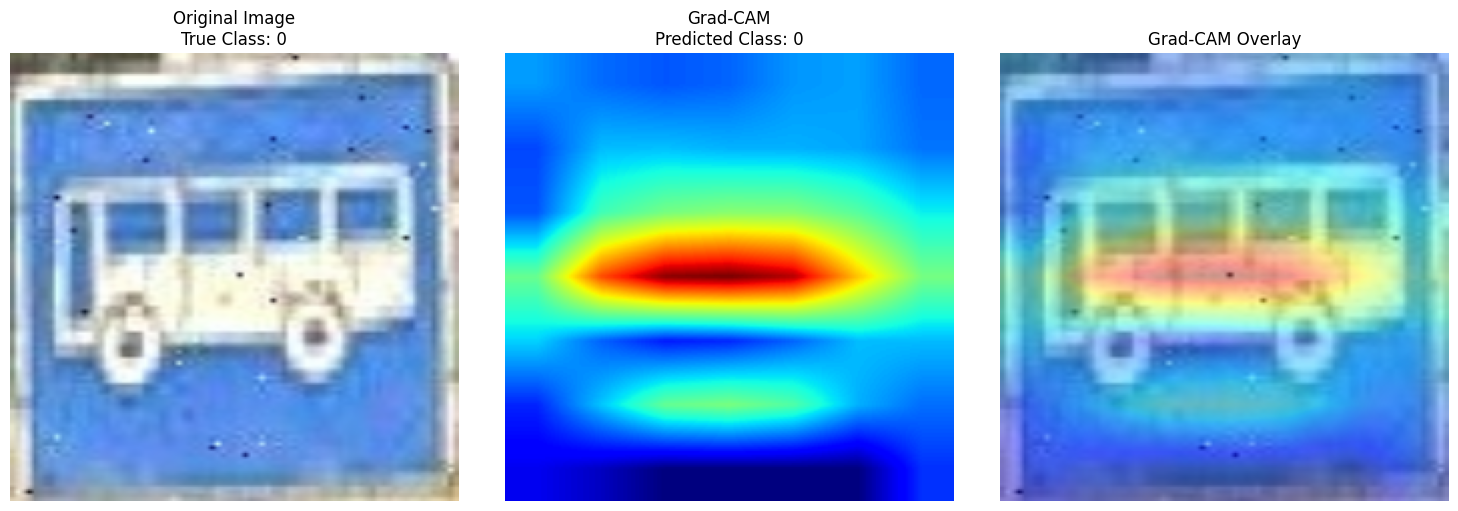

Saved: /content/efficientnetv2s_gradcam_sample.png


In [ ]:
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.imshow(original_display)
plt.title(f"Original Image\nTrue Class: {true_class}")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(heatmap_resized, cmap="jet")
plt.title(f"Grad-CAM\nPredicted Class: {predicted_class}")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(overlay)
plt.title("Grad-CAM Overlay")
plt.axis("off")

plt.tight_layout()

plt.savefig(
    "/content/efficientnetv2s_gradcam_sample.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved: /content/efficientnetv2s_gradcam_sample.png")

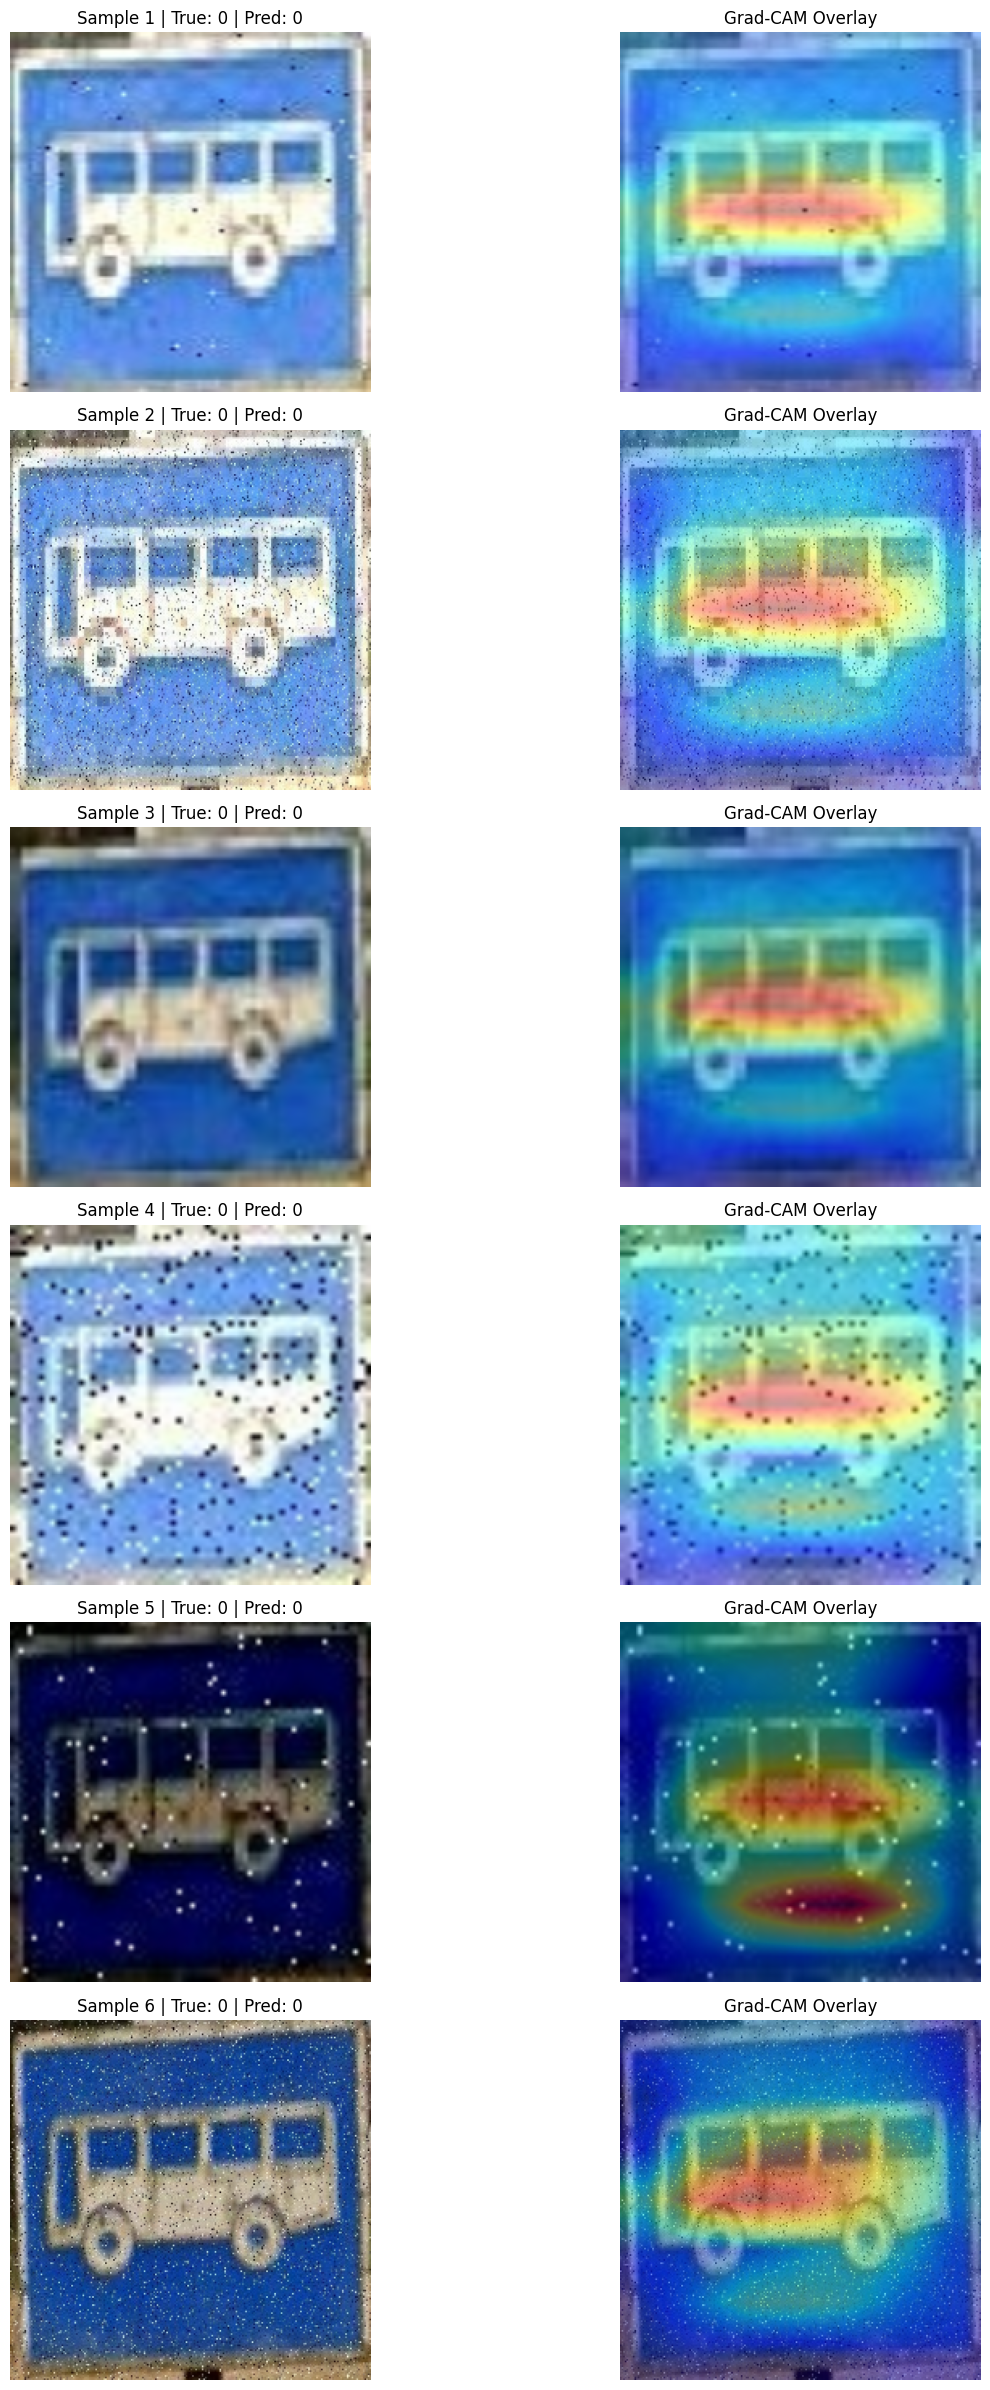

In [ ]:
num_samples = 6

plt.figure(figsize=(15, num_samples * 4))

for i in range(num_samples):

    img = images[i]
    img_array = tf.expand_dims(img, axis=0)

    # Grad-CAM
    heatmap, predicted_class = make_gradcam_heatmap_fixed(
        img_array,
        model,
        base_model,
        last_conv_layer_name
    )

    true_class = int(tf.argmax(labels[i]).numpy())

    original = img.numpy() if tf.is_tensor(img) else img
    original = np.array(original)

    if original.max() <= 1.5:
        original_display = np.clip(original, 0, 1)
    else:
        original_display = np.clip(original / 255.0, 0, 1)

       heatmap_resized = tf.image.resize(
        heatmap[..., tf.newaxis],
        (original_display.shape[0], original_display.shape[1])
    ).numpy().squeeze()

     plt.subplot(num_samples, 2, 2*i + 1)
    plt.imshow(original_display)
    plt.title(
        f"Sample {i+1} | True: {true_class} | Pred: {predicted_class}"
    )
    plt.axis("off")

    plt.subplot(num_samples, 2, 2*i + 2)
    plt.imshow(original_display)
    plt.imshow(heatmap_resized, cmap="jet", alpha=0.4)
    plt.title("Grad-CAM Overlay")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
correct = 0
incorrect = 0

for i in range(len(images)):

    img_array = tf.expand_dims(images[i], axis=0)

    prediction = model.predict(img_array, verbose=0)

    predicted_class = int(np.argmax(prediction[0]))
    true_class = int(tf.argmax(labels[i]).numpy())

    if predicted_class == true_class:
        correct += 1
    else:
        incorrect += 1

print("Correct predictions :", correct)
print("Incorrect predictions:", incorrect)

Correct predictions : 22
Incorrect predictions: 10


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for images_batch, labels_batch in test_ds:

    predictions = model.predict(images_batch, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(np.argmax(labels_batch.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total test samples:", len(y_true))

Total test samples: 409


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

y_true = []
y_pred = []

for images_batch, labels_batch in test_ds:

    predictions = model.predict(images_batch, verbose=0)

    y_pred.extend(np.argmax(predictions, axis=1))
    y_true.extend(np.argmax(labels_batch.numpy(), axis=1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

print("Total test samples:", len(y_true))

Total test samples: 409


In [ ]:
from sklearn.metrics import classification_report

report = classification_report(
    y_true,
    y_pred,
    digits=4
)

print(report)

              precision    recall  f1-score   support

           0     0.8400    0.9545    0.8936        22
           1     0.0000    0.0000    0.0000         2
           2     0.7500    0.1765    0.2857        17
           3     1.0000    1.0000    1.0000         7
           4     1.0000    0.7500    0.8571        16
           5     1.0000    1.0000    1.0000         4
           6     1.0000    0.6000    0.7500         5
           7     1.0000    1.0000    1.0000         2
           8     0.9677    1.0000    0.9836        30
           9     0.6667    1.0000    0.8000         2
          10     1.0000    1.0000    1.0000        11
          11     1.0000    1.0000    1.0000         8
          12     0.6000    1.0000    0.7500         3
          13     0.5000    1.0000    0.6667         3
          14     0.4286    1.0000    0.6000         3
          15     1.0000    0.8462    0.9167        26
          16     1.0000    0.5000    0.6667         2
          17     0.7077    

In [ ]:
from sklearn.metrics import accuracy_score
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import f1_score

accuracy = accuracy_score(y_true, y_pred)

weighted_precision = precision_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_recall = recall_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

weighted_f1 = f1_score(
    y_true,
    y_pred,
    average="weighted",
    zero_division=0
)

print("=" * 60)
print("EFFICIENTNETV2-S FINAL TEST METRICS")
print("=" * 60)

print(f"Accuracy           : {accuracy * 100:.2f}%")
print(f"Weighted Precision : {weighted_precision:.4f}")
print(f"Weighted Recall    : {weighted_recall:.4f}")
print(f"Weighted F1        : {weighted_f1:.4f}")

EFFICIENTNETV2-S FINAL TEST METRICS
Accuracy           : 79.71%
Weighted Precision : 0.8241
Weighted Recall    : 0.7971
Weighted F1        : 0.7818


In [ ]:
import time
import numpy as np

# Warm-up
for _ in range(5):
    _ = model.predict(
        tf.expand_dims(images[0], axis=0),
        verbose=0
    )

times = []

for _ in range(30):

    start = time.perf_counter()

    _ = model.predict(
        tf.expand_dims(images[0], axis=0),
        verbose=0
    )

    end = time.perf_counter()

    times.append(end - start)

avg_single_image_time = np.mean(times)

print("=" * 60)
print("SINGLE IMAGE INFERENCE TIME")
print("=" * 60)

print(f"Average time : {avg_single_image_time:.6f} seconds")
print(f"Average time : {avg_single_image_time * 1000:.2f} ms/image")

SINGLE IMAGE INFERENCE TIME
Average time : 0.085644 seconds
Average time : 85.64 ms/image


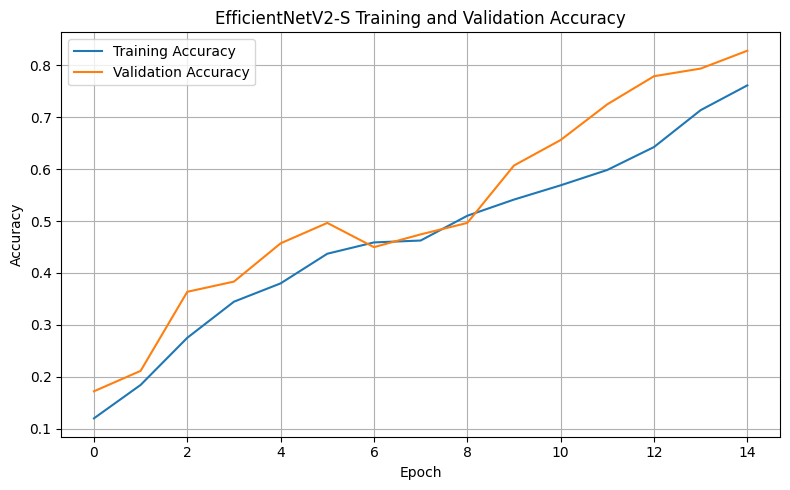

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("EfficientNetV2-S Training and Validation Accuracy")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

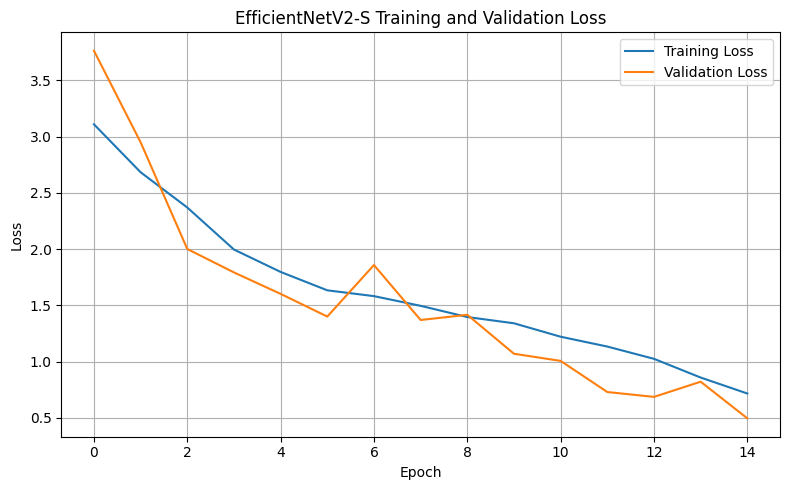

In [ ]:
plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("EfficientNetV2-S Training and Validation Loss")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

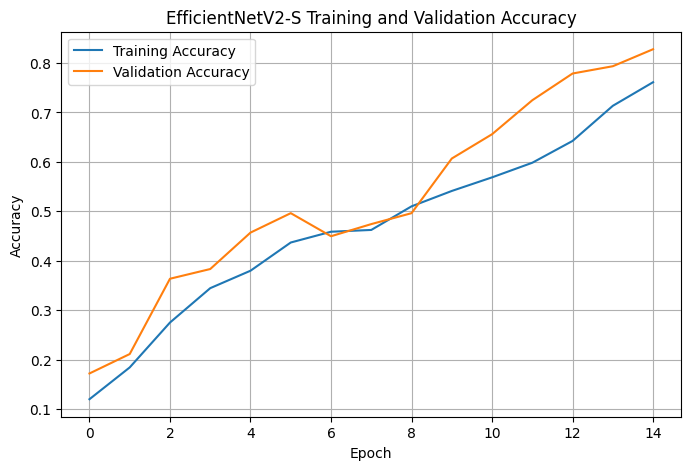

In [ ]:
import matplotlib.pyplot as plt

# Accuracy curve
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('EfficientNetV2-S Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

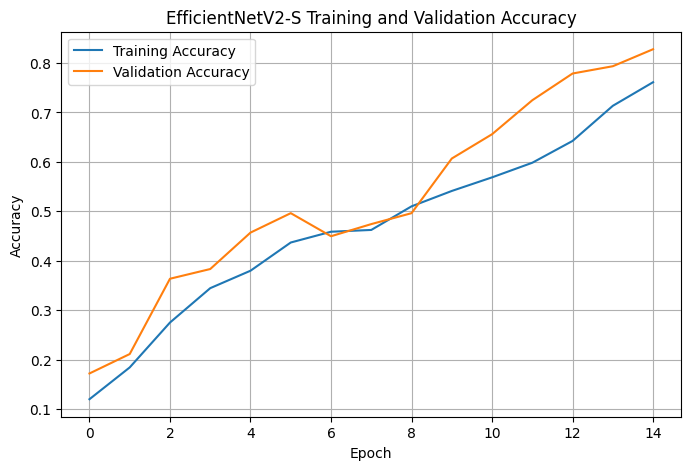

In [ ]:
import matplotlib.pyplot as plt

# Accuracy curve
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('EfficientNetV2-S Training and Validation Accuracy')
plt.legend()
plt.grid(True)

plt.show()

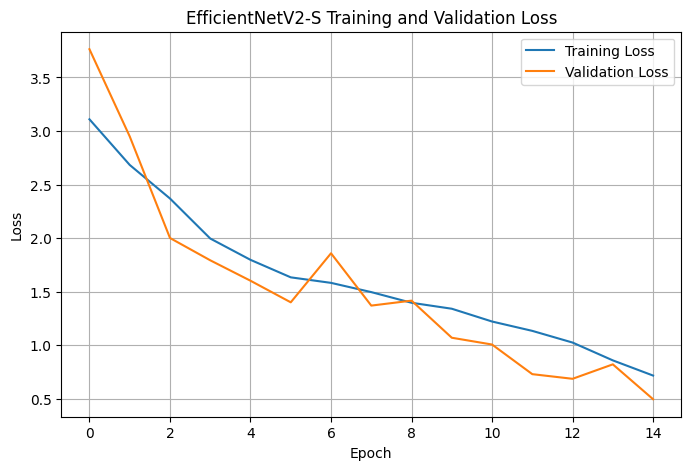

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('EfficientNetV2-S Training and Validation Loss')
plt.legend()
plt.grid(True)

plt.show()

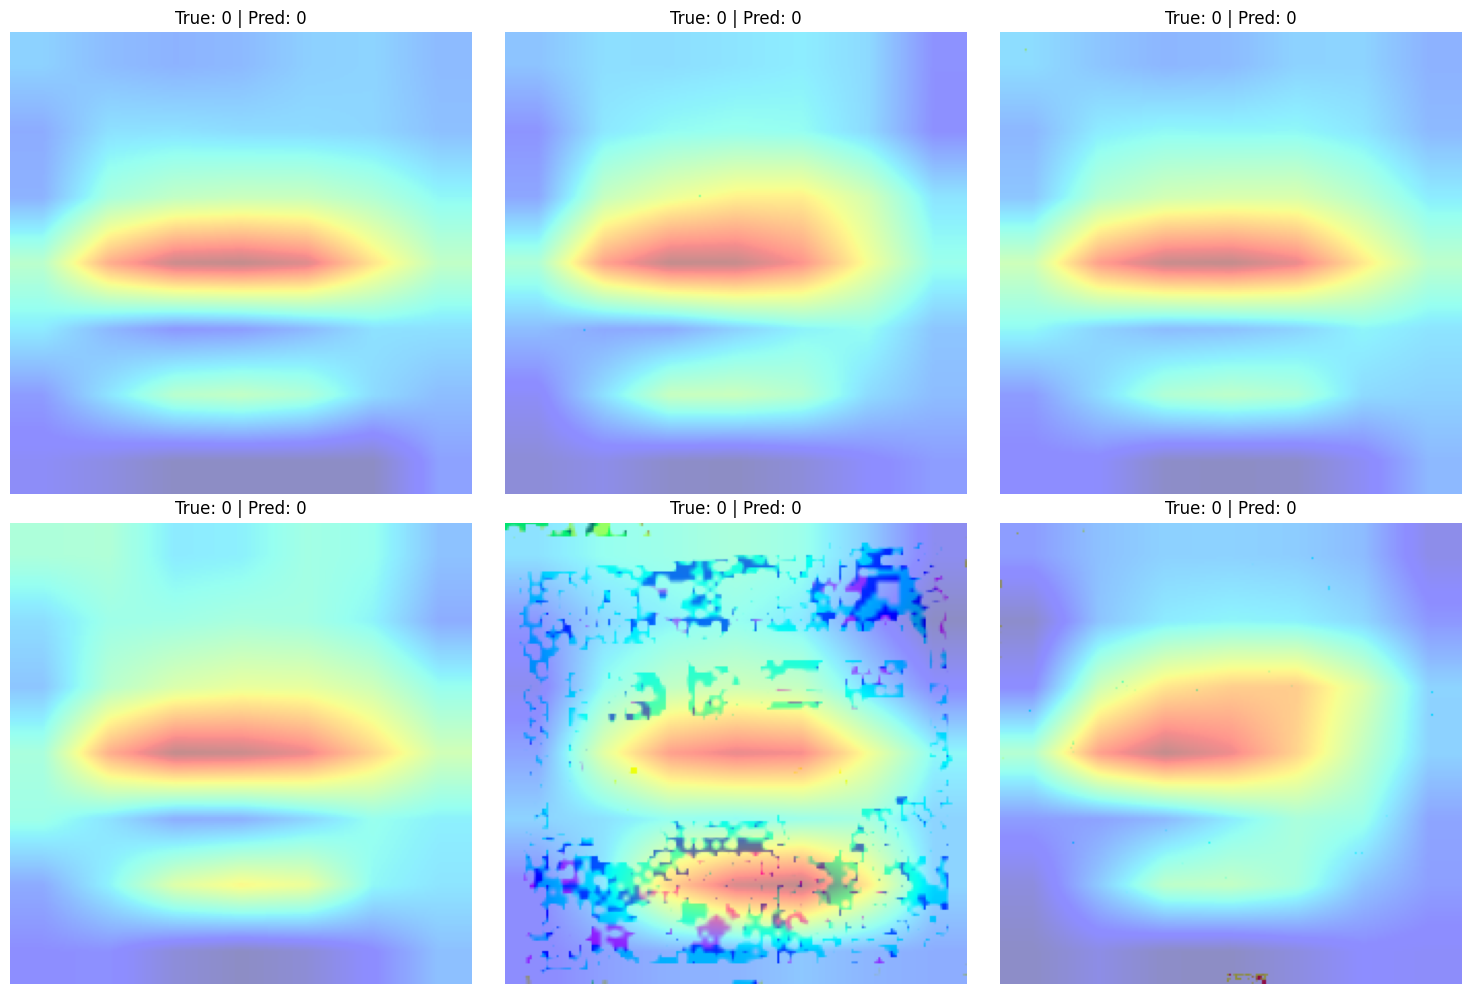

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

# Take one batch from test dataset
images, labels = next(iter(test_ds))

num_samples = min(6, images.shape[0])

plt.figure(figsize=(15, 10))

for i in range(num_samples):

    img = images[i]
    img_array = tf.expand_dims(img, axis=0)

    # Grad-CAM
    heatmap, predicted_class = make_gradcam_heatmap_fixed(
        img_array,
        model,
        base_model,
        last_conv_layer_name
    )


    true_class = int(tf.argmax(labels[i]).numpy())

        original = img.numpy()

        original = np.clip(original, 0, 1)

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    ax = plt.subplot(2, 3, i + 1)

    ax.imshow(original)
    ax.imshow(
        heatmap_resized,
        cmap='jet',
        alpha=0.45
    )

    ax.set_title(
        f"True: {true_class} | Pred: {predicted_class}"
    )

    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

images, labels = next(iter(test_ds))

predictions = model.predict(images, verbose=0)

predicted_classes = np.argmax(predictions, axis=1)
true_classes = np.argmax(labels.numpy(), axis=1)

correct_indices = np.where(
    predicted_classes == true_classes
)[0]

incorrect_indices = np.where(
    predicted_classes != true_classes
)[0]

print("Correct samples available :", len(correct_indices))
print("Incorrect samples available :", len(incorrect_indices))

Correct samples available : 22
Incorrect samples available : 10


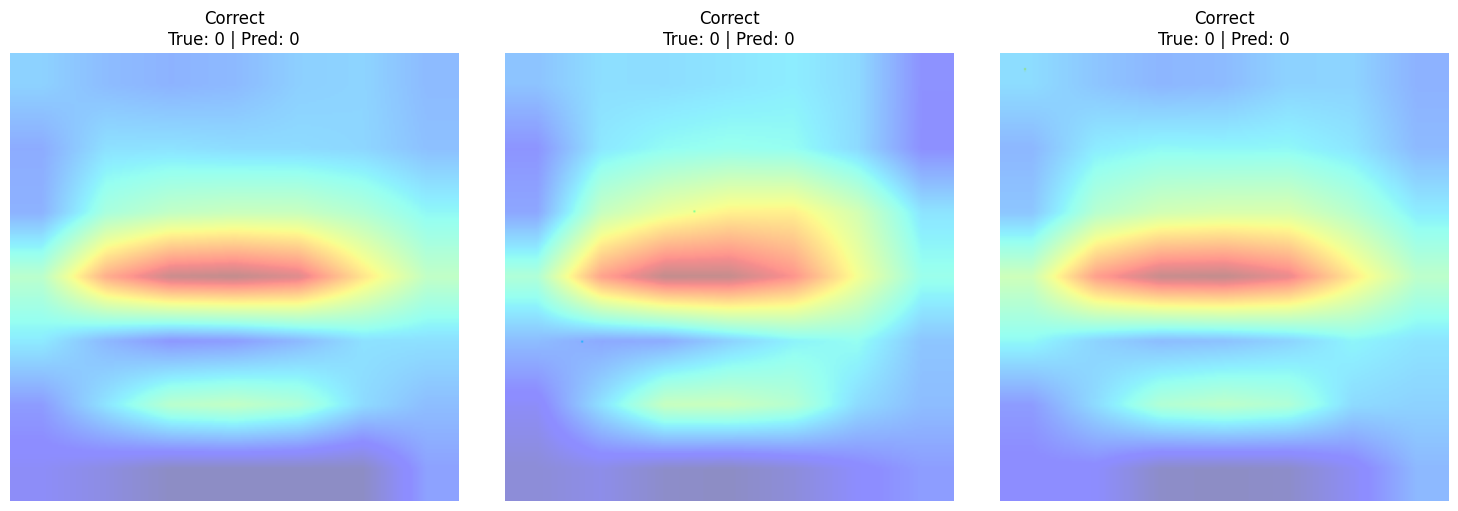

In [ ]:
num_samples = min(3, len(correct_indices))

plt.figure(figsize=(15, 5))

for j in range(num_samples):

    i = correct_indices[j]

    img = images[i]
    img_array = tf.expand_dims(img, axis=0)

    heatmap, predicted_class = make_gradcam_heatmap_fixed(
        img_array,
        model,
        base_model,
        last_conv_layer_name
    )

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    original = np.clip(img.numpy(), 0, 1)

    ax = plt.subplot(1, 3, j + 1)

    ax.imshow(original)
    ax.imshow(
        heatmap_resized,
        cmap='jet',
        alpha=0.45
    )

    ax.set_title(
        f"Correct\nTrue: {true_classes[i]} | Pred: {predicted_classes[i]}"
    )

    ax.axis('off')

plt.tight_layout()
plt.show()

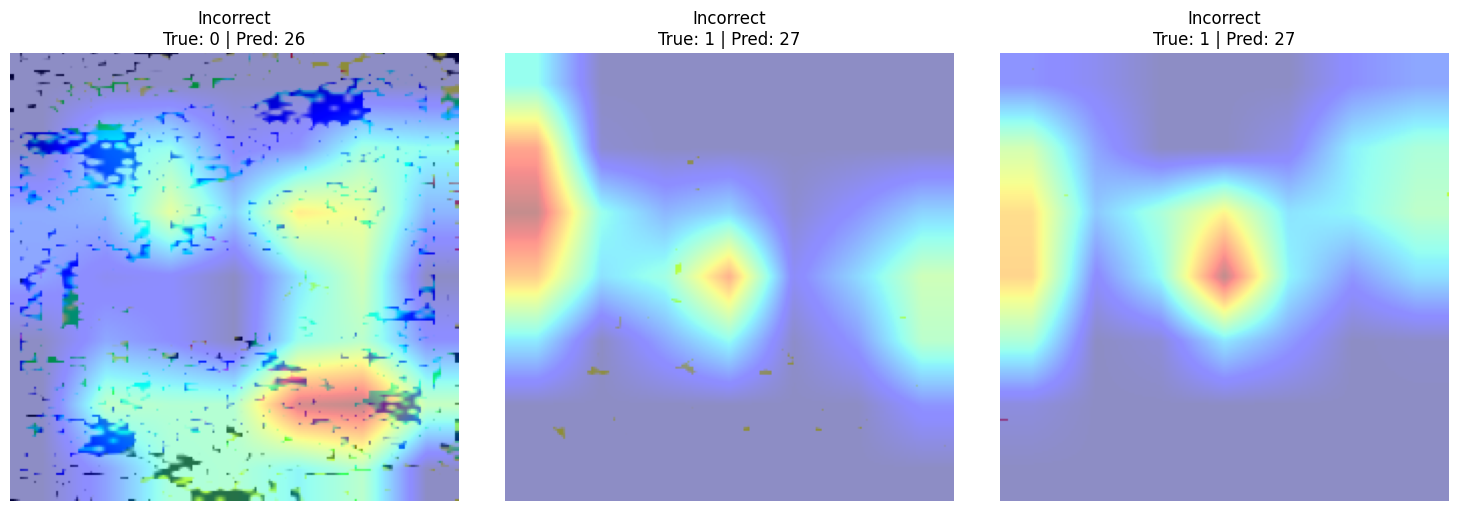

In [ ]:
num_samples = min(3, len(incorrect_indices))

plt.figure(figsize=(15, 5))

for j in range(num_samples):

    i = incorrect_indices[j]

    img = images[i]
    img_array = tf.expand_dims(img, axis=0)

    heatmap, predicted_class = make_gradcam_heatmap_fixed(
        img_array,
        model,
        base_model,
        last_conv_layer_name
    )

    heatmap_resized = tf.image.resize(
        heatmap[..., np.newaxis],
        (224, 224)
    ).numpy().squeeze()

    original = np.clip(img.numpy(), 0, 1)

    ax = plt.subplot(1, 3, j + 1)

    ax.imshow(original)
    ax.imshow(
        heatmap_resized,
        cmap='jet',
        alpha=0.45
    )

    ax.set_title(
        f"Incorrect\nTrue: {true_classes[i]} | Pred: {predicted_classes[i]}"
    )

    ax.axis('off')

plt.tight_layout()
plt.show()

In [ ]:

img = images[0]
img_array = tf.expand_dims(img, axis=0)

pred_probs = model.predict(
    img_array,
    verbose=0
)[0]

predicted_class = np.argmax(pred_probs)
confidence = pred_probs[predicted_class] * 100

true_class = int(
    tf.argmax(labels[0]).numpy()
)

heatmap, _ = make_gradcam_heatmap_fixed(
    img_array,
    model,
    base_model,
    last_conv_layer_name
)

print("True Class       :", true_class)
print("Predicted Class  :", predicted_class)
print("Confidence       : {:.2f}%".format(confidence))

True Class       : 0
Predicted Class  : 0
Confidence       : 99.99%


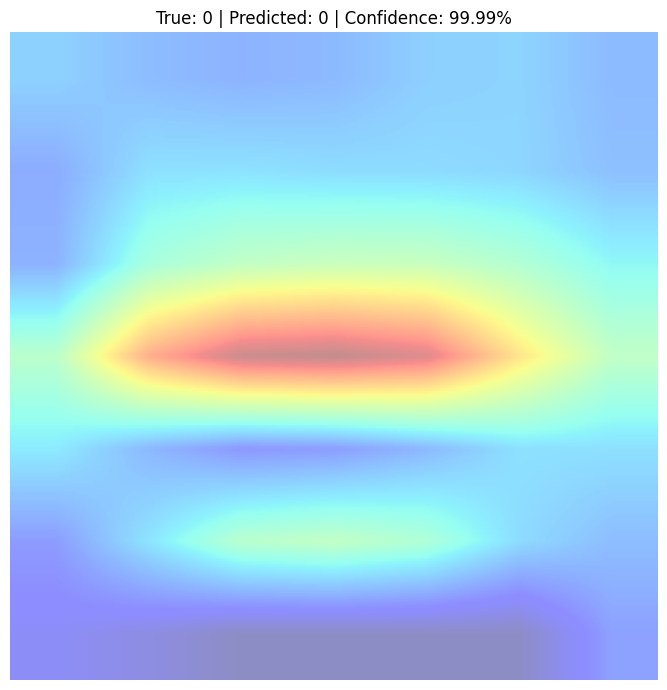

In [ ]:
heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

original = np.clip(
    img.numpy(),
    0,
    1
)

plt.figure(figsize=(7, 7))

plt.imshow(original)

plt.imshow(
    heatmap_resized,
    cmap='jet',
    alpha=0.45
)

plt.title(
    f"True: {true_class} | "
    f"Predicted: {predicted_class} | "
    f"Confidence: {confidence:.2f}%"
)

plt.axis('off')

plt.tight_layout()

plt.savefig(
    '/content/efficientnetv2s_gradcam_confidence.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
import numpy as np

class_accuracy = []

for class_id in range(28):

    indices = np.where(y_true == class_id)[0]

    if len(indices) > 0:
        acc = np.mean(
            y_pred[indices] == y_true[indices]
        )
    else:
        acc = 0

    class_accuracy.append(acc)

print("Per-Class Accuracy")
print("==============================")

for class_id, acc in enumerate(class_accuracy):

    print(
        f"Class {class_id:2d} : "
        f"{acc*100:.2f}%"
    )

Per-Class Accuracy
Class  0 : 95.45%
Class  1 : 0.00%
Class  2 : 17.65%
Class  3 : 100.00%
Class  4 : 75.00%
Class  5 : 100.00%
Class  6 : 60.00%
Class  7 : 100.00%
Class  8 : 100.00%
Class  9 : 100.00%
Class 10 : 100.00%
Class 11 : 100.00%
Class 12 : 100.00%
Class 13 : 100.00%
Class 14 : 100.00%
Class 15 : 84.62%
Class 16 : 50.00%
Class 17 : 92.00%
Class 18 : 0.00%
Class 19 : 83.33%
Class 20 : 39.39%
Class 21 : 81.25%
Class 22 : 100.00%
Class 23 : 89.47%
Class 24 : 81.48%
Class 25 : 100.00%
Class 26 : 100.00%
Class 27 : 88.89%


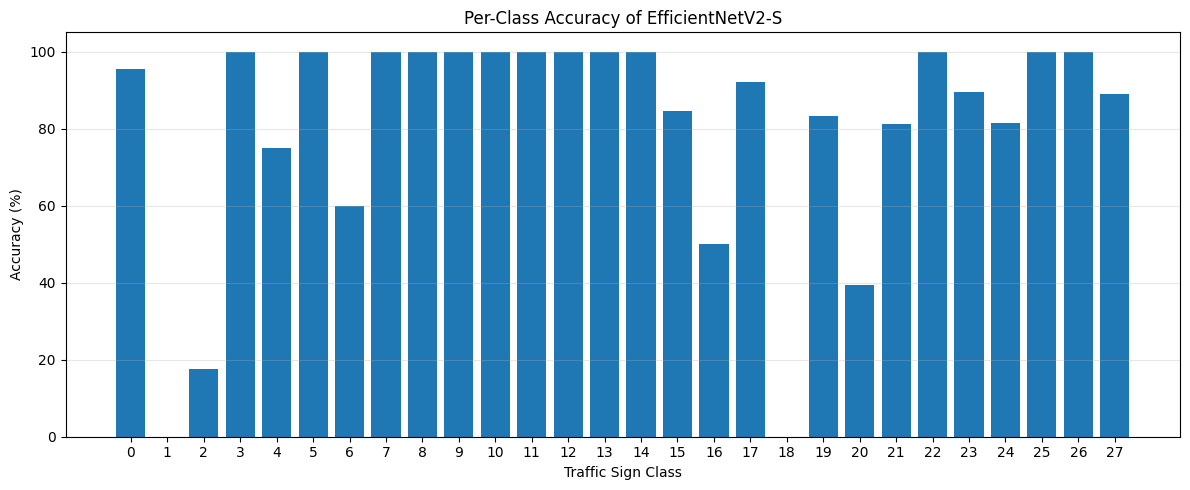

In [ ]:
plt.figure(figsize=(12, 5))

plt.bar(
    range(28),
    np.array(class_accuracy) * 100
)

plt.xlabel("Traffic Sign Class")
plt.ylabel("Accuracy (%)")
plt.title("Per-Class Accuracy of EfficientNetV2-S")

plt.xticks(range(28))

plt.grid(
    axis='y',
    alpha=0.3
)

plt.tight_layout()

plt.savefig(
    '/content/efficientnetv2s_per_class_accuracy.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [ ]:
best_class = int(np.argmax(class_accuracy))
worst_class = int(np.argmin(class_accuracy))

print(
    f"Best performing class  : {best_class} "
    f"({class_accuracy[best_class]*100:.2f}%)"
)

print(
    f"Worst performing class : {worst_class} "
    f"({class_accuracy[worst_class]*100:.2f}%)"
)

Best performing class  : 3 (100.00%)
Worst performing class : 1 (0.00%)


In [ ]:
best_class = int(np.argmax(class_accuracy))
worst_class = int(np.argmin(class_accuracy))

print(
    f"Best performing class  : {best_class} "
    f"({class_accuracy[best_class]*100:.2f}%)"
)

print(
    f"Worst performing class : {worst_class} "
    f"({class_accuracy[worst_class]*100:.2f}%)"
)

Best performing class  : 3 (100.00%)
Worst performing class : 1 (0.00%)


In [ ]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

final_accuracy = accuracy_score(y_true, y_pred)

final_precision = precision_score(
    y_true,
    y_pred,
    average='weighted',
    zero_division=0
)

final_recall = recall_score(
    y_true,
    y_pred,
    average='weighted',
    zero_division=0
)

final_f1 = f1_score(
    y_true,
    y_pred,
    average='weighted',
    zero_division=0
)

print("=" * 65)
print("EFFICIENTNETV2-S FINAL TEST METRICS")
print("=" * 65)

print(f"Accuracy           : {final_accuracy*100:.2f}%")
print(f"Weighted Precision : {final_precision:.4f}")
print(f"Weighted Recall    : {final_recall:.4f}")
print(f"Weighted F1        : {final_f1:.4f}")

EFFICIENTNETV2-S FINAL TEST METRICS
Accuracy           : 79.71%
Weighted Precision : 0.8241
Weighted Recall    : 0.7971
Weighted F1        : 0.7818


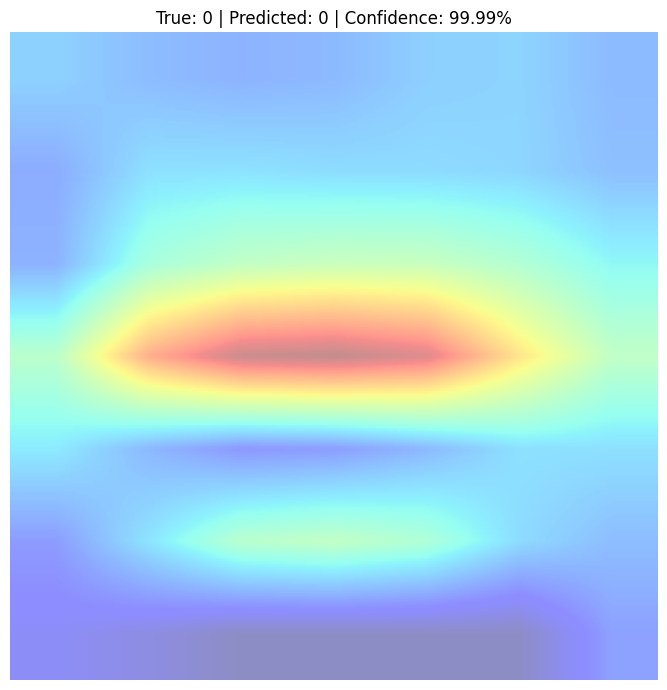

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf

images, labels = next(iter(test_ds))

img = images[0]
img_array = tf.expand_dims(img, axis=0)

heatmap, predicted_class = make_gradcam_heatmap_fixed(
    img_array,
    model,
    base_model,
    last_conv_layer_name
)

true_class = int(tf.argmax(labels[0]).numpy())

pred_probs = model.predict(img_array, verbose=0)[0]
confidence = float(pred_probs[predicted_class]) * 100

heatmap_resized = tf.image.resize(
    heatmap[..., np.newaxis],
    (224, 224)
).numpy().squeeze()

original = np.clip(img.numpy(), 0, 1)

plt.figure(figsize=(7,7))
plt.imshow(original)
plt.imshow(
    heatmap_resized,
    cmap='jet',
    alpha=0.45
)

plt.title(
    f"True: {true_class} | "
    f"Predicted: {predicted_class} | "
    f"Confidence: {confidence:.2f}%"
)

plt.axis("off")
plt.tight_layout()

plt.savefig(
    "/content/EfficientNetV2S_GradCAM_Final.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
model.save(
    "/content/EfficientNetV2S_Bangladesh_Traffic_Signs.keras"
)

print("EfficientNetV2-S model saved successfully.")

EfficientNetV2-S model saved successfully.


In [ ]:
import pandas as pd

final_summary = pd.DataFrame({
    "Model": ["EfficientNetV2-S"],
    "Accuracy (%)": [final_accuracy * 100],
    "Weighted Precision": [final_precision],
    "Weighted Recall": [final_recall],
    "Weighted F1": [final_f1]
})

print(final_summary.to_string(index=False))

           Model  Accuracy (%)  Weighted Precision  Weighted Recall  Weighted F1
EfficientNetV2-S     79.706601            0.824061         0.797066     0.781779


In [ ]:
import time
import numpy as np
import tensorflow as tf




print("Model:", model.name)

# Use test dataset
print("Benchmarking on test dataset...")

warmup_batches = 3

for i, (images, labels) in enumerate(test_ds.take(warmup_batches)):
    _ = model(images, training=False)


try:
    tf.experimental.async_wait()
except:
    pass



total_images = 0
total_time = 0.0

for images, labels in test_ds:

    batch_size = images.shape[0]

    start_time = time.perf_counter()

    # ONLY forward-pass inference
    predictions = model(images, training=False)

    # Force TensorFlow to finish computation
    _ = predictions.numpy()

    end_time = time.perf_counter()

    batch_time = end_time - start_time

    total_time += batch_time
    total_images += batch_size


avg_time_per_image = total_time / total_images
ms_per_image = avg_time_per_image * 1000
images_per_second = total_images / total_time

print("\n" + "=" * 65)
print("EFFICIENTNETV2-S — TRUE INFERENCE BENCHMARK")
print("=" * 65)

print(f"Total test images       : {total_images}")
print(f"Total forward-pass time : {total_time:.6f} seconds")
print(f"Average time/image      : {ms_per_image:.4f} ms")
print(f"Throughput              : {images_per_second:.2f} images/sec")

print("=" * 65)

Model: EfficientNetV2S_TSR
Benchmarking on test dataset...

EFFICIENTNETV2-S — TRUE INFERENCE BENCHMARK
Total test images       : 409
Total forward-pass time : 21.505039 seconds
Average time/image      : 52.5796 ms
Throughput              : 19.02 images/sec


In [ ]:
import time
import numpy as np
import tensorflow as tf

# ============================================================
# EFFICIENTNETV2-S — SINGLE IMAGE FORWARD-PASS BENCHMARK
# ============================================================

# Take one real test image
sample_images, sample_labels = next(iter(test_ds))

single_image = sample_images[0:1]   # shape: (1, 224, 224, 3)

for _ in range(10):
    output = model(single_image, training=False)
    _ = output.numpy()


num_runs = 100

times = []

for _ in range(num_runs):

    start = time.perf_counter()

    output = model(single_image, training=False)

    # Force computation to finish
    _ = output.numpy()

    end = time.perf_counter()

    times.append(end - start)

times = np.array(times)


mean_ms = np.mean(times) * 1000
median_ms = np.median(times) * 1000
std_ms = np.std(times) * 1000
min_ms = np.min(times) * 1000
max_ms = np.max(times) * 1000

print("\n" + "=" * 65)
print("EFFICIENTNETV2-S — SINGLE IMAGE INFERENCE BENCHMARK")
print("=" * 65)

print(f"Runs                  : {num_runs}")
print(f"Mean latency          : {mean_ms:.4f} ms/image")
print(f"Median latency        : {median_ms:.4f} ms/image")
print(f"Standard deviation    : {std_ms:.4f} ms")
print(f"Minimum latency       : {min_ms:.4f} ms")
print(f"Maximum latency       : {max_ms:.4f} ms")

print("=" * 65)


EFFICIENTNETV2-S — SINGLE IMAGE INFERENCE BENCHMARK
Runs                  : 100
Mean latency          : 641.8651 ms/image
Median latency        : 596.2385 ms/image
Standard deviation    : 90.2613 ms
Minimum latency       : 563.6577 ms
Maximum latency       : 891.0868 ms


In [ ]:
import time
import numpy as np
import tensorflow as tf

# ============================================================
# CONTROLLED EFFICIENTNETV2-S GPU BENCHMARK
# ============================================================

# Take one full batch from test set
images, labels = next(iter(test_ds))

print("Benchmark batch shape:", images.shape)


for _ in range(20):
    y = model(images, training=False)
    _ = y.numpy()


num_runs = 100
times = []

for _ in range(num_runs):

    start = time.perf_counter()

    y = model(images, training=False)

    # Synchronize TensorFlow computation
    _ = y.numpy()

    end = time.perf_counter()

    times.append(end - start)

times = np.array(times)

batch_size = images.shape[0]

# Remove first few potentially unstable measurements
stable_times = times[10:]

mean_batch = np.mean(stable_times)
median_batch = np.median(stable_times)

mean_per_image = mean_batch / batch_size
median_per_image = median_batch / batch_size

throughput = batch_size / mean_batch

print("\n" + "=" * 70)
print("EFFICIENTNETV2-S — CONTROLLED GPU INFERENCE BENCHMARK")
print("=" * 70)

print(f"Batch size             : {batch_size}")
print(f"Runs                   : {len(stable_times)}")
print(f"Mean batch latency     : {mean_batch:.6f} sec")
print(f"Median batch latency   : {median_batch:.6f} sec")
print(f"Mean per-image latency : {mean_per_image*1000:.4f} ms")
print(f"Median per-image       : {median_per_image*1000:.4f} ms")
print(f"Throughput             : {throughput:.2f} images/sec")

print("=" * 70)

Benchmark batch shape: (32, 224, 224, 3)

EFFICIENTNETV2-S — CONTROLLED GPU INFERENCE BENCHMARK
Batch size             : 32
Runs                   : 90
Mean batch latency     : 0.638741 sec
Median batch latency   : 0.596011 sec
Mean per-image latency : 19.9607 ms
Median per-image       : 18.6253 ms
Throughput             : 50.10 images/sec


In [ ]:
# ============================================================
# EXACT GRAD-CAM FOR YOUR EfficientNetV2S_TSR MODEL
# ============================================================

# Get exact layers from your model
augmentation_layer = model.get_layer("data_augmentation")
rescaling_layer = model.get_layer("rescaling_1")
backbone = model.get_layer("efficientnetv2-s")
gap_layer = model.get_layer("global_average_pooling2d_1")
classifier = model.get_layer("dense_1")

print("Architecture confirmed:")
print("Augmentation :", augmentation_layer.name)
print("Rescaling    :", rescaling_layer.name)
print("Backbone     :", backbone.name)
print("Backbone out :", backbone.output.shape)
print("GAP          :", gap_layer.name)
print("Classifier   :", classifier.name)
print("Classes      :", classifier.units)


# ============================================================
# GRAD-CAM FUNCTION
# ============================================================

def generate_gradcam_exact(image):

    # Make sure image is float32
    image = tf.cast(image, tf.float32)

    # Add batch dimension
    img_batch = tf.expand_dims(image, axis=0)

  

    with tf.GradientTape() as tape:

        # Input -> augmentation
        x = augmentation_layer(
            img_batch,
            training=False
        )

        # Augmentation -> rescaling
        x = rescaling_layer(
            x,
            training=False
        )

        # Rescaling -> EfficientNetV2-S
        backbone_features = backbone(
            x,
            training=False
        )

        # Tell GradientTape to watch the feature maps
        tape.watch(backbone_features)

        # Feature maps -> Global Average Pooling
        pooled_features = gap_layer(
            backbone_features
        )

        # GAP -> Dense classifier
        predictions = classifier(
            pooled_features
        )

        # Predicted class
        predicted_class = tf.argmax(
            predictions[0]
        )

        # Score of predicted class
        class_score = predictions[:, predicted_class]

  

    grads = tape.gradient(
        class_score,
        backbone_features
    )

    if grads is None:
        raise ValueError(
            "Gradient is None. "
            "Please check the model graph."
        )


    pooled_grads = tf.reduce_mean(
        grads,
        axis=(1, 2)
    )

    # Remove batch dimension
    feature_maps = backbone_features[0]
    pooled_grads = pooled_grads[0]


    heatmap = tf.reduce_sum(
        feature_maps * pooled_grads,
        axis=-1
    )

    # ReLU
    heatmap = tf.maximum(
        heatmap,
        0
    )

    # Normalize
    max_heatmap = tf.reduce_max(
        heatmap
    )

    heatmap = tf.where(
        max_heatmap > 0,
        heatmap / max_heatmap,
        tf.zeros_like(heatmap)
    )

    # Resize 7x7 -> 224x224
    heatmap = tf.image.resize(
        heatmap[..., tf.newaxis],
        (224, 224)
    )

    heatmap = tf.squeeze(
        heatmap,
        axis=-1
    )

    return (
        heatmap.numpy(),
        int(predicted_class.numpy())
    )



print("\nTesting Grad-CAM on first test image...")

for images, labels in test_ds.take(1):

    test_image = images[0]

    heatmap, predicted_class = generate_gradcam_exact(
        test_image
    )

    print("\nSUCCESS!")
    print("Heatmap shape :", heatmap.shape)
    print("Predicted class:", predicted_class)
    print("Heatmap min   :", float(heatmap.min()))
    print("Heatmap max   :", float(heatmap.max()))
    print("Heatmap mean  :", float(heatmap.mean()))

    break

Architecture confirmed:
Augmentation : data_augmentation
Rescaling    : rescaling_1
Backbone     : efficientnetv2-s
Backbone out : (None, 7, 7, 1280)
GAP          : global_average_pooling2d_1
Classifier   : dense_1
Classes      : 28

Testing Grad-CAM on first test image...

SUCCESS!
Heatmap shape : (224, 224)
Predicted class: 0
Heatmap min   : 0.0
Heatmap max   : 0.992100179195404
Heatmap mean  : 0.3356224000453949


In [ ]:
# ============================================================
# QUANTITATIVE GRAD-CAM ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
from collections import defaultdict

# ------------------------------------------------------------
# Metric settings
# ------------------------------------------------------------

THRESHOLD = 0.5

results = []

# Store heatmaps by TRUE class
class_heatmaps = defaultdict(list)

# ------------------------------------------------------------
# Process complete test set
# ------------------------------------------------------------

total_images = 0

for batch_images, batch_labels in test_ds:

    batch_size = batch_images.shape[0]

    for i in range(batch_size):

        image = batch_images[i]

        # --------------------------------------------
        # Grad-CAM
        # --------------------------------------------

        heatmap, predicted_class = generate_gradcam_exact(
            image
        )

        # --------------------------------------------
        # True label
        # --------------------------------------------

        label = batch_labels[i]

        # Handle one-hot labels
        if len(label.shape) > 0 and label.shape[-1] > 1:
            true_class = int(
                tf.argmax(label).numpy()
            )
        else:
            true_class = int(
                tf.reshape(label, [-1])[0].numpy()
            )

        # --------------------------------------------
        # Important Pixels Percentage
        # --------------------------------------------

        important_pixels = np.sum(
            heatmap >= THRESHOLD
        )

        total_pixels = heatmap.size

        important_pixel_percentage = (
            important_pixels / total_pixels
        ) * 100.0

        # --------------------------------------------
        # Average Heatmap Intensity
        # --------------------------------------------

        average_heatmap_intensity = float(
            np.mean(heatmap)
        )

        # --------------------------------------------
        # Store heatmap by TRUE class
        # --------------------------------------------

        class_heatmaps[true_class].append(
            heatmap.flatten()
        )

        # --------------------------------------------
        # Store sample result
        # --------------------------------------------

        results.append({
            "true_class": true_class,
            "predicted_class": predicted_class,
            "correct": int(
                true_class == predicted_class
            ),
            "important_pixels_percentage":
                important_pixel_percentage,
            "average_heatmap_intensity":
                average_heatmap_intensity
        })

        total_images += 1

        if total_images % 50 == 0:
            print(
                f"Processed {total_images} images..."
            )


# ------------------------------------------------------------
# Convert to DataFrame
# ------------------------------------------------------------

gradcam_df = pd.DataFrame(results)

print("\n" + "=" * 65)
print("QUANTITATIVE GRAD-CAM RESULTS")
print("=" * 65)

print("Total images:", len(gradcam_df))

print(
    "\nMean Important Pixels Percentage:",
    f"{gradcam_df['important_pixels_percentage'].mean():.4f}%"
)

print(
    "Mean Average Heatmap Intensity:",
    f"{gradcam_df['average_heatmap_intensity'].mean():.4f}"
)

print(
    "Prediction Accuracy in Grad-CAM run:",
    f"{gradcam_df['correct'].mean() * 100:.2f}%"
)


# ============================================================
# CLASS-WISE ATTENTION CONSISTENCY
# ============================================================

class_consistency = []

for class_id, heatmaps in class_heatmaps.items():

    heatmaps = np.asarray(heatmaps)

    # Need at least 2 samples for pairwise consistency
    if len(heatmaps) < 2:
        continue

    # Normalize each heatmap vector
    norms = np.linalg.norm(
        heatmaps,
        axis=1,
        keepdims=True
    )

    normalized_heatmaps = (
        heatmaps /
        np.maximum(norms, 1e-8)
    )

    # Class centroid
    centroid = np.mean(
        normalized_heatmaps,
        axis=0
    )

    centroid_norm = np.linalg.norm(
        centroid
    )

    centroid = centroid / max(
        centroid_norm,
        1e-8
    )

    # Cosine similarity with class centroid
    similarities = np.dot(
        normalized_heatmaps,
        centroid
    )

    mean_consistency = float(
        np.mean(similarities)
    )

    class_consistency.append({
        "class_id": class_id,
        "num_images": len(heatmaps),
        "attention_consistency":
            mean_consistency
    })


class_consistency_df = pd.DataFrame(
    class_consistency
)


print("\n" + "=" * 65)
print("CLASS-WISE ATTENTION CONSISTENCY")
print("=" * 65)

print(
    class_consistency_df.to_string(
        index=False
    )
)


# ============================================================
# OVERALL ATTENTION CONSISTENCY
# ============================================================

overall_consistency = float(
    class_consistency_df[
        "attention_consistency"
    ].mean()
)

print("\n" + "=" * 65)
print("OVERALL ATTENTION CONSISTENCY")
print("=" * 65)

print(
    f"{overall_consistency:.4f}"
)

Processed 50 images...
Processed 100 images...
Processed 150 images...
Processed 200 images...
Processed 250 images...
Processed 300 images...
Processed 350 images...
Processed 400 images...

QUANTITATIVE GRAD-CAM RESULTS
Total images: 409

Mean Important Pixels Percentage: 22.2859%
Mean Average Heatmap Intensity: 0.2870
Prediction Accuracy in Grad-CAM run: 79.71%

CLASS-WISE ATTENTION CONSISTENCY
 class_id  num_images  attention_consistency
        0          22               0.921047
        1           2               0.962861
        2          17               0.741210
        3           7               0.924176
        4          16               0.771180
        5           4               0.990557
        6           5               0.851038
        7           2               0.997620
        8          30               0.915116
        9           2               0.969485
       10          11               0.978432
       11           8               0.937341
       12     

In [ ]:
# ============================================================
# EFFICIENTNETV2-S GRAD-CAM FINAL RESULTS
# SAVE + SUMMARY
# ============================================================

gradcam_df.to_csv(
    "EfficientNetV2S_GradCAM_sample_results.csv",
    index=False
)

class_consistency_df.to_csv(
    "EfficientNetV2S_Classwise_Attention_Consistency.csv",
    index=False
)



gradcam_summary = pd.DataFrame({
    "Metric": [
        "Test Images",
        "Important Pixels Percentage (%)",
        "Average Heatmap Intensity",
        "Overall Attention Consistency",
        "Prediction Accuracy (%)"
    ],
    "Value": [
        len(gradcam_df),
        gradcam_df[
            "important_pixels_percentage"
        ].mean(),
        gradcam_df[
            "average_heatmap_intensity"
        ].mean(),
        overall_consistency,
        gradcam_df[
            "correct"
        ].mean() * 100
    ]
})



print("\n" + "=" * 70)
print("EFFICIENTNETV2-S — FINAL QUANTITATIVE GRAD-CAM RESULTS")
print("=" * 70)

print(
    gradcam_summary.to_string(index=False)
)



gradcam_summary.to_csv(
    "EfficientNetV2S_GradCAM_Final_Summary.csv",
    index=False
)

print("\n" + "=" * 70)
print("FILES SAVED")
print("=" * 70)

print("1. EfficientNetV2S_GradCAM_sample_results.csv")
print("2. EfficientNetV2S_Classwise_Attention_Consistency.csv")
print("3. EfficientNetV2S_GradCAM_Final_Summary.csv")


EFFICIENTNETV2-S — FINAL QUANTITATIVE GRAD-CAM RESULTS
                         Metric      Value
                    Test Images 409.000000
Important Pixels Percentage (%)  22.285896
      Average Heatmap Intensity   0.287045
  Overall Attention Consistency   0.890967
        Prediction Accuracy (%)  79.706601

FILES SAVED
1. EfficientNetV2S_GradCAM_sample_results.csv
2. EfficientNetV2S_Classwise_Attention_Consistency.csv
3. EfficientNetV2S_GradCAM_Final_Summary.csv


In [ ]:
# ============================================================
# STEP 1 — FIND EXISTING MODEL OBJECTS
# ============================================================

import tensorflow as tf

print("=" * 70)
print("EXISTING MODEL OBJECTS IN CURRENT COLAB SESSION")
print("=" * 70)

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    try:
        if isinstance(obj, tf.keras.Model):
            print(f"\nVariable: {name}")
            print(f"Type    : {type(obj).__name__}")
            print(f"Input   : {obj.input_shape}")
            print(f"Output  : {obj.output_shape}")

    except Exception:
        pass


print("\n" + "=" * 70)
print("DATASET OBJECTS")
print("=" * 70)

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    try:
        if isinstance(obj, tf.data.Dataset):
            print(f"{name} -> tf.data.Dataset")
    except Exception:
        pass

EXISTING MODEL OBJECTS IN CURRENT COLAB SESSION

Variable: base_model
Type    : Functional
Input   : (None, 224, 224, 3)
Output  : (None, 7, 7, 1280)

Variable: model
Type    : Functional
Input   : (None, 224, 224, 3)
Output  : (None, 28)

Variable: data_augmentation
Type    : Sequential
Input   : (None, 224, 224, 3)
Output  : (None, 224, 224, 3)

Variable: target_layer
Type    : Functional
Input   : (None, 224, 224, 3)
Output  : (None, 7, 7, 1280)

Variable: grad_model
Type    : Functional
Input   : (None, 224, 224, 3)
Output  : [(None, 7, 7, 1280), (None, 28)]

Variable: gradcam_model
Type    : Functional
Input   : (None, 224, 224, 3)
Output  : [(None, 7, 7, 1280), (None, 7, 7, 1280)]

Variable: augmentation_layer
Type    : Sequential
Input   : (None, 224, 224, 3)
Output  : (None, 224, 224, 3)

Variable: backbone
Type    : Functional
Input   : (None, 224, 224, 3)
Output  : (None, 7, 7, 1280)

DATASET OBJECTS
train_ds -> tf.data.Dataset
valid_ds -> tf.data.Dataset
test_ds -> tf.data.D

In [ ]:
print("=" * 80)
print("EFFICIENTNETV2-S REPRODUCIBILITY INFORMATION")
print("=" * 80)

# Model configuration
print("\n[1] MODEL INPUT / OUTPUT")
print("Input shape :", model.input_shape)
print("Output shape:", model.output_shape)

# Optimizer
print("\n[2] OPTIMIZER")
print("Optimizer:", type(model.optimizer).__name__)

try:
    print("Learning rate:",
          float(tf.keras.backend.get_value(model.optimizer.learning_rate)))
except:
    print("Learning rate: Could not read")

# Loss and metrics
print("\n[3] COMPILE CONFIGURATION")
print("Loss   :", model.loss)
print("Metrics:", model.metrics_names)

# Trainable status
print("\n[4] TRAINABLE LAYERS")
trainable_count = 0
nontrainable_count = 0

for layer in model.layers:
    if layer.trainable:
        trainable_count += 1
    else:
        nontrainable_count += 1

print("Trainable top-level layers    :", trainable_count)
print("Non-trainable top-level layers:", nontrainable_count)

# Backbone information
print("\n[5] BACKBONE")
print("Backbone name   :", base_model.name)
print("Backbone trainable:", base_model.trainable)

trainable_backbone = sum(1 for l in base_model.layers if l.trainable)
frozen_backbone = sum(1 for l in base_model.layers if not l.trainable)

print("Backbone total layers      :", len(base_model.layers))
print("Backbone trainable layers  :", trainable_backbone)
print("Backbone frozen layers     :", frozen_backbone)

# First/last few backbone layers
print("\n[6] BACKBONE LAYER STATUS")
for i, layer in enumerate(base_model.layers[:5]):
    print(i, layer.name, "| trainable =", layer.trainable)

print("...")

for i, layer in list(enumerate(base_model.layers))[-5:]:
    print(i, layer.name, "| trainable =", layer.trainable)

# Dataset cardinality
print("\n[7] DATASET BATCH INFORMATION")

for name, ds in [
    ("train_ds", train_ds),
    ("valid_ds", valid_ds),
    ("test_ds", test_ds)
]:
    try:
        cardinality = tf.data.experimental.cardinality(ds).numpy()
        print(f"{name:10s}: {cardinality} batches")
    except:
        print(f"{name:10s}: Could not determine")

# One batch
print("\n[8] BATCH SHAPE")

images, labels = next(iter(test_ds))

print("Test images shape:", images.shape)
print("Test labels shape:", labels.shape)

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

EFFICIENTNETV2-S REPRODUCIBILITY INFORMATION

[1] MODEL INPUT / OUTPUT
Input shape : (None, 224, 224, 3)
Output shape: (None, 28)

[2] OPTIMIZER
Optimizer: Adam
Learning rate: 0.0010000000474974513

[3] COMPILE CONFIGURATION
Loss   : categorical_crossentropy
Metrics: ['loss', 'compile_metrics']

[4] TRAINABLE LAYERS
Trainable top-level layers    : 6
Non-trainable top-level layers: 0

[5] BACKBONE
Backbone name   : efficientnetv2-s
Backbone trainable: True
Backbone total layers      : 512
Backbone trainable layers  : 512
Backbone frozen layers     : 0

[6] BACKBONE LAYER STATUS
0 input_layer | trainable = True
1 stem_conv | trainable = True
2 stem_bn | trainable = True
3 stem_activation | trainable = True
4 block1a_project_conv | trainable = True
...
507 block6o_drop | trainable = True
508 block6o_add | trainable = True
509 top_conv | trainable = True
510 top_bn | trainable = True
511 top_activation | trainable = True

[7] DATASET BATCH INFORMATION
train_ds  : 61 batches
valid_ds  : 13 

In [ ]:
print("=" * 80)
print("EFFICIENTNETV2-S CALLBACK & REPRODUCIBILITY CHECK")
print("=" * 80)

print("\n[1] CALLBACK VARIABLES")

callback_names = [
    "callbacks",
    "callback",
    "early_stopping",
    "earlystop",
    "early_stop",
    "reduce_lr",
    "lr_scheduler"
]

found = False

for name in callback_names:
    if name in globals():
        obj = globals()[name]
        print("\nVariable:", name)
        print("Type    :", type(obj).__name__)

        if isinstance(obj, (list, tuple)):
            for i, cb in enumerate(obj):
                print("  Callback", i, ":", type(cb).__name__)

                if isinstance(cb, tf.keras.callbacks.EarlyStopping):
                    print("    monitor              :", cb.monitor)
                    print("    patience             :", cb.patience)
                    print("    restore_best_weights :", cb.restore_best_weights)
                    print("    min_delta             :", cb.min_delta)

                if isinstance(cb, tf.keras.callbacks.ReduceLROnPlateau):
                    print("    monitor :", cb.monitor)
                    print("    patience:", cb.patience)
                    print("    factor  :", cb.factor)
        else:
            if isinstance(obj, tf.keras.callbacks.EarlyStopping):
                print("  monitor              :", obj.monitor)
                print("  patience             :", obj.patience)
                print("  restore_best_weights :", obj.restore_best_weights)
                print("  min_delta             :", obj.min_delta)

            if isinstance(obj, tf.keras.callbacks.ReduceLROnPlateau):
                print("  monitor :", obj.monitor)
                print("  patience:", obj.patience)
                print("  factor  :", obj.factor)

        found = True

if not found:
    print("No common callback variable found.")


# --------------------------------------------------
# 2. Check common seed variables
# --------------------------------------------------
print("\n[2] RANDOM SEED")

seed_names = [
    "SEED",
    "seed",
    "RANDOM_SEED",
    "random_seed"
]

seed_found = False

for name in seed_names:
    if name in globals():
        print(name, "=", globals()[name])
        seed_found = True

if not seed_found:
    print("No explicit seed variable found.")


print("\n[3] TRAINING HISTORY")

print("Epochs recorded:", len(history.history["loss"]))

best_epoch = int(
    tf.math.argmin(history.history["val_loss"]).numpy()
) + 1

best_val_loss = history.history["val_loss"][best_epoch - 1]
best_val_accuracy = history.history["val_accuracy"][best_epoch - 1]

print("Best validation-loss epoch :", best_epoch)
print("Best validation loss       :", best_val_loss)
print("Validation accuracy there  :", best_val_accuracy)

print("\nLast epoch:")
print("Training accuracy :", history.history["accuracy"][-1])
print("Training loss     :", history.history["loss"][-1])
print("Validation accuracy:", history.history["val_accuracy"][-1])
print("Validation loss    :", history.history["val_loss"][-1])

print("\n" + "=" * 80)
print("DONE")
print("=" * 80)

EFFICIENTNETV2-S CALLBACK & REPRODUCIBILITY CHECK

[1] CALLBACK VARIABLES
No common callback variable found.

[2] RANDOM SEED
SEED = 42

[3] TRAINING HISTORY
Epochs recorded: 15
Best validation-loss epoch : 15
Best validation loss       : 0.49607136845588684
Validation accuracy there  : 0.828009843826294

Last epoch:
Training accuracy : 0.7612869739532471
Training loss     : 0.716827929019928
Validation accuracy: 0.828009843826294
Validation loss    : 0.49607136845588684

DONE


In [ ]:
print("=" * 80)
print("SEARCHING FOR OTHER MODEL OBJECTS")
print("=" * 80)

import tensorflow as tf

model_keywords = [
    "lenet",
    "cnn",
    "sequential",
    "mobile",
    "mobilenet"
]

found_models = []

# Snapshot নেওয়া হচ্ছে যাতে globals() changed error না হয়
global_items = list(globals().items())

for name, obj in global_items:

    if isinstance(obj, tf.keras.Model):

        name_lower = name.lower()

        if any(keyword in name_lower for keyword in model_keywords):

            found_models.append((name, obj))

            print("\nVariable:", name)
            print("Type    :", type(obj).__name__)
            print("Input   :", obj.input_shape)
            print("Output  :", obj.output_shape)
            print("Params  :", obj.count_params())


print("\n" + "=" * 80)

if len(found_models) == 0:
    print("NO OTHER MODEL OBJECTS FOUND.")
else:
    print("OTHER MODELS FOUND:", len(found_models))

print("=" * 80)